In [1]:
import scipy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import os

In [2]:
from pathlib import Path

folder1 = Path("raw_data/Arithmetic_Data_")
arithmetic_all_files = list(folder1.glob("*.txt"))

folder2 = Path("raw_data/Stroop_Data")
stroop_all_files = list(folder2.glob("*.txt"))

data1 = {
    "highlevel": [],
    "midlevel": [],
    "lowlevel": [],
    "natural": []
}

data2 = {
    "highlevel": [],
    "midlevel": [],
    "lowlevel": [],
    "natural": []
}

for file in arithmetic_all_files:

    df = pd.read_csv(file,header=None)

    if file.name.startswith("highlevel"):
        data1["highlevel"].append(df)

    elif file.name.startswith("midlevel"):
        data1["midlevel"].append(df)

    elif file.name.startswith("lowlevel"):
        data1["lowlevel"].append(df)

    elif file.name.startswith("natural"):
        data1["natural"].append(df)

for file in stroop_all_files:

    df = pd.read_csv(file,header=None)

    if file.name.startswith("highlevel"):
        data2["highlevel"].append(df)

    elif file.name.startswith("midlevel"):
        data2["midlevel"].append(df)

    elif file.name.startswith("lowlevel"):
        data2["lowlevel"].append(df)

    elif file.name.startswith("natural"):
        data2["natural"].append(df)



In [3]:
headers = [
    "Sample_Index",
    "FP1", "FP2", "F7", "F3",
    "FZ", "F4", "F8", "C4",
    "Accel_X", "Accel_Y", "Accel_Z",
    "Sampling_Rate", "Meta_1", "Meta_2", "Meta_3",
    "Meta_4", "Meta_5", "Meta_6", "Meta_7", "Meta_8", "Meta_9",
    "Unix_Timestamp",
    "Status",
    "DateTime"
]

In [4]:
for key in data1.keys():
    for df in data1[key]:
        df.columns = headers

        if file.name.startswith("highlevel"): df["Stress_Level"] = "high"

        elif file.name.startswith("midlevel"): df["Stress_Level"] = "mid"

        elif file.name.startswith("lowlevel"): df["Stress_Level"] = "low"

        elif file.name.startswith("natural"): df["Stress_Level"] = "natural"


for key in data2.keys():
    for df in data2[key]:
        df.columns = headers

        if file.name.startswith("highlevel"): df["Stress_Level"] = "high"

        elif file.name.startswith("midlevel"): df["Stress_Level"] = "mid"

        elif file.name.startswith("lowlevel"): df["Stress_Level"] = "low"

        elif file.name.startswith("natural"): df["Stress_Level"] = "natural"



### Creates Arithmetic raw CSVs.

In [5]:
import os

base_arithmetic_dir = "Dataset/Raw/Arithmetic"
os.makedirs(base_arithmetic_dir, exist_ok=True)

for category in data1.keys():

    category_dir = os.path.join(base_arithmetic_dir, category)
    os.makedirs(category_dir, exist_ok=True)

    for i, df in enumerate(data1[category], start=1):

        filepath = os.path.join(category_dir, f"{category}_{i}.csv")
        df.to_csv(filepath, index=False)

    print(f"All Files Saved for Category: {category}")

All Files Saved for Category: highlevel
All Files Saved for Category: midlevel
All Files Saved for Category: lowlevel
All Files Saved for Category: natural


### Creates Stroop raw CSVs.

In [6]:
base_stroop_dir = "Dataset/Raw/Stroop"

os.makedirs(base_stroop_dir, exist_ok=True)

for category in data2.keys():
    category_dir = os.path.join(base_stroop_dir, category)
    os.makedirs(category_dir, exist_ok=True)

    for i, df in enumerate(data2[category], start=1):
        filepath = os.path.join(category_dir,f"{category}_{i}.csv")
        df.to_csv(filepath, index=False)

    print(f"All Files Saved for Category: {category}")

All Files Saved for Category: highlevel
All Files Saved for Category: midlevel
All Files Saved for Category: lowlevel
All Files Saved for Category: natural


### Creates Arithmetic clean CSVs.

In [7]:
clean_base_arithmetic_dir = "Dataset/Clean/Arithmetic"
os.makedirs(clean_base_arithmetic_dir, exist_ok=True)

eeg_cols = ["FP1","FP2","F7","F3","FZ","F4","F8","C4","Sampling_Rate"]

for category in data1.keys():

    category_dir = os.path.join(clean_base_arithmetic_dir, category)
    os.makedirs(category_dir, exist_ok=True)

    for subject_id, df in enumerate(data1[category], start=1):

        clean_df = df[eeg_cols].copy()

        # Remove startup row
        clean_df = clean_df.iloc[1:].reset_index(drop=True)

        clean_df["Stress_Level"] = category
        clean_df["Subject_ID"] = subject_id

        filepath = os.path.join(category_dir,f"{category}_{subject_id}.csv")

        clean_df.to_csv(filepath, index=False)
    print(f"All Files Saved for Category: {category}")

print("All clean files created successfully.")

All Files Saved for Category: highlevel
All Files Saved for Category: midlevel
All Files Saved for Category: lowlevel
All Files Saved for Category: natural
All clean files created successfully.


##### For Testing

In [8]:
filepath = "Dataset/Clean/Arithmetic/highlevel/highlevel_4.csv"
df = pd.read_csv(filepath)
df['Sampling_Rate'].value_counts()

Sampling_Rate
192.0    29459
Name: count, dtype: int64

In [9]:
base_dir = "Dataset/Clean/Arithmetic"

for category in os.listdir(base_dir):

    category_path = os.path.join(base_dir, category)

    if not os.path.isdir(category_path):
        continue

    for file in os.listdir(category_path):

        if file.endswith(".csv"):

            df = pd.read_csv(
                os.path.join(category_path, file)
            )

            fs = df["Sampling_Rate"].iloc[5]
            value_count = df['Sampling_Rate'].value_counts()
            if fs == 196.0:
                print(file)
                print(fs)
                print(value_count)



### Creates Stroop clean CSVs.

In [10]:
clean_base_stroop_dir = "Dataset/Clean/Stroop"

os.makedirs(clean_base_stroop_dir, exist_ok=True)

eeg_cols = ["FP1","FP2","F7","F3","FZ","F4","F8","C4","Sampling_Rate"]

for category in data2.keys():

    category_dir = os.path.join(clean_base_stroop_dir, category)
    os.makedirs(category_dir, exist_ok=True)

    for subject_id, df in enumerate(data2[category], start=1):

        clean_df = df[eeg_cols].copy()

        # Remove startup row
        clean_df = clean_df.iloc[1:].reset_index(drop=True)

        clean_df["Stress_Level"] = category
        clean_df["Subject_ID"] = subject_id

        filepath = os.path.join(
            category_dir,
            f"{category}_{subject_id}.csv"
        )

        clean_df.to_csv(filepath, index=False)

    print(f"All Files Saved for Category: {category}")

print("All clean files created successfully.")

All Files Saved for Category: highlevel
All Files Saved for Category: midlevel
All Files Saved for Category: lowlevel
All Files Saved for Category: natural
All clean files created successfully.


### EDA for Arithmetic & Stroop sample.

In [11]:
filepath = os.path.join("Dataset/Clean/Arithmetic/highlevel/highlevel_1.csv")
sample1 = pd.read_csv(filepath)

print("="*50)
print("SHAPE")
print(sample1.shape)

print("\n"+"="*50)
print("MISSING VALUES")
print(sample1.isnull().sum())

print("\n"+"="*50)
print("DUPLICATE ROWS")
print(sample1.duplicated().sum())

print("\n"+"="*50)
print("SUMMARY STATISTICS")
print(sample1.describe())

SHAPE
(29329, 11)

MISSING VALUES
FP1              0
FP2              0
F7               0
F3               0
FZ               0
F4               0
F8               0
C4               0
Sampling_Rate    0
Stress_Level     0
Subject_ID       0
dtype: int64

DUPLICATE ROWS
0

SUMMARY STATISTICS
                FP1           FP2            F7            F3            FZ  \
count  29329.000000  29329.000000  29329.000000  29329.000000  29329.000000   
mean   31000.319076  29896.571190  31908.825171  21248.267899  21740.470325   
std       51.338693     56.722563    114.840309     40.602592     40.365583   
min    30720.662263  29597.732973  31646.225649  21153.310973  21634.812252   
25%    30961.882289  29854.398054  31790.975546  21221.819070  21711.657549   
50%    31016.219379  29920.492163  31936.418347  21243.746131  21745.475739   
75%    31037.766461  29938.865297  32010.849656  21262.253375  21773.996565   
max    31103.547645  29986.407457  32094.400477  21454.076046  21822.65631

In [12]:
filepath2 = os.path.join("Dataset/Clean/Stroop/highlevel/highlevel_1.csv")
sample2 = pd.read_csv(filepath2)

print("="*50)
print("SHAPE")
print(sample2.shape)

print("\n"+"="*50)
print("MISSING VALUES")
print(sample2.isnull().sum())

print("\n"+"="*50)
print("DUPLICATE ROWS")
print(sample2.duplicated().sum())

print("\n"+"="*50)
print("SUMMARY STATISTICS")
print(sample2.describe())

SHAPE
(28167, 11)

MISSING VALUES
FP1              0
FP2              0
F7               0
F3               0
FZ               0
F4               0
F8               0
C4               0
Sampling_Rate    0
Stress_Level     0
Subject_ID       0
dtype: int64

DUPLICATE ROWS
0

SUMMARY STATISTICS
                FP1           FP2            F7            F3            FZ  \
count  28167.000000  28167.000000  28167.000000  28167.000000  28167.000000   
mean   30814.252671  29667.233700  31067.836919  21312.348907  21514.839911   
std      130.851761    126.186384    112.676537     99.020105     47.011164   
min    30512.791039  29372.673258  30899.655032  21177.763781  21417.530944   
25%    30729.580609  29593.776714  30999.947309  21243.835538  21477.768895   
50%    30764.203461  29614.943816  31018.923941  21265.896710  21501.193524   
75%    30865.155115  29709.178771  31081.743518  21361.394538  21560.190953   
max    31141.478555  29989.044963  31385.134922  21548.199242  21622.65290

### EEG Channels Used in Dataset

In [13]:
eeg_channels = [
    "FP1","FP2","F7","F3",
    "FZ","F4","F8","C4"
]

Arithmetic Data Graph


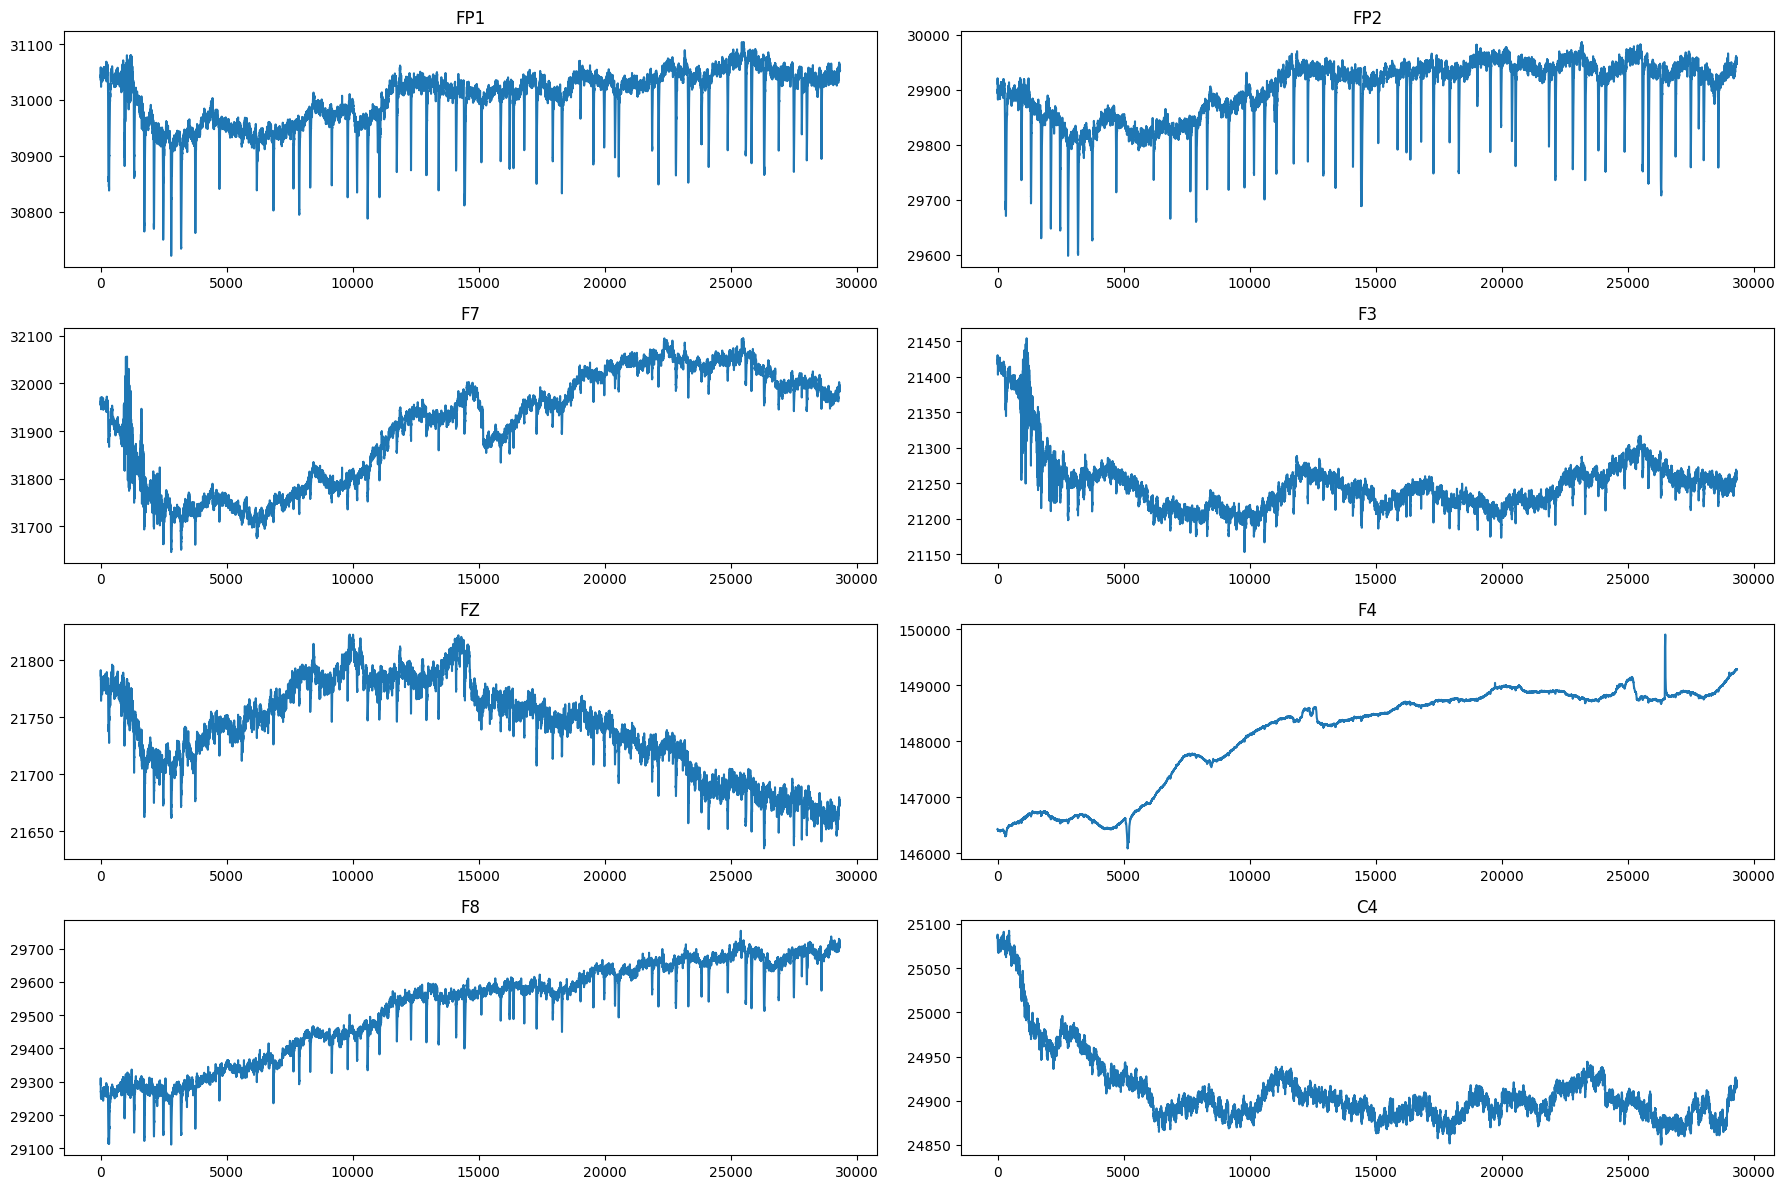

In [14]:
sample1 = pd.read_csv("Dataset/Clean/Arithmetic/highlevel/highlevel_1.csv")

plt.figure(figsize=(18,12))

for i,col in enumerate(eeg_channels,start=1):

    plt.subplot(4,2,i)
    plt.plot(sample1[col])
    plt.title(col)

plt.tight_layout()
print("Arithmetic Data Graph")
plt.show()

Stroop Data Graph


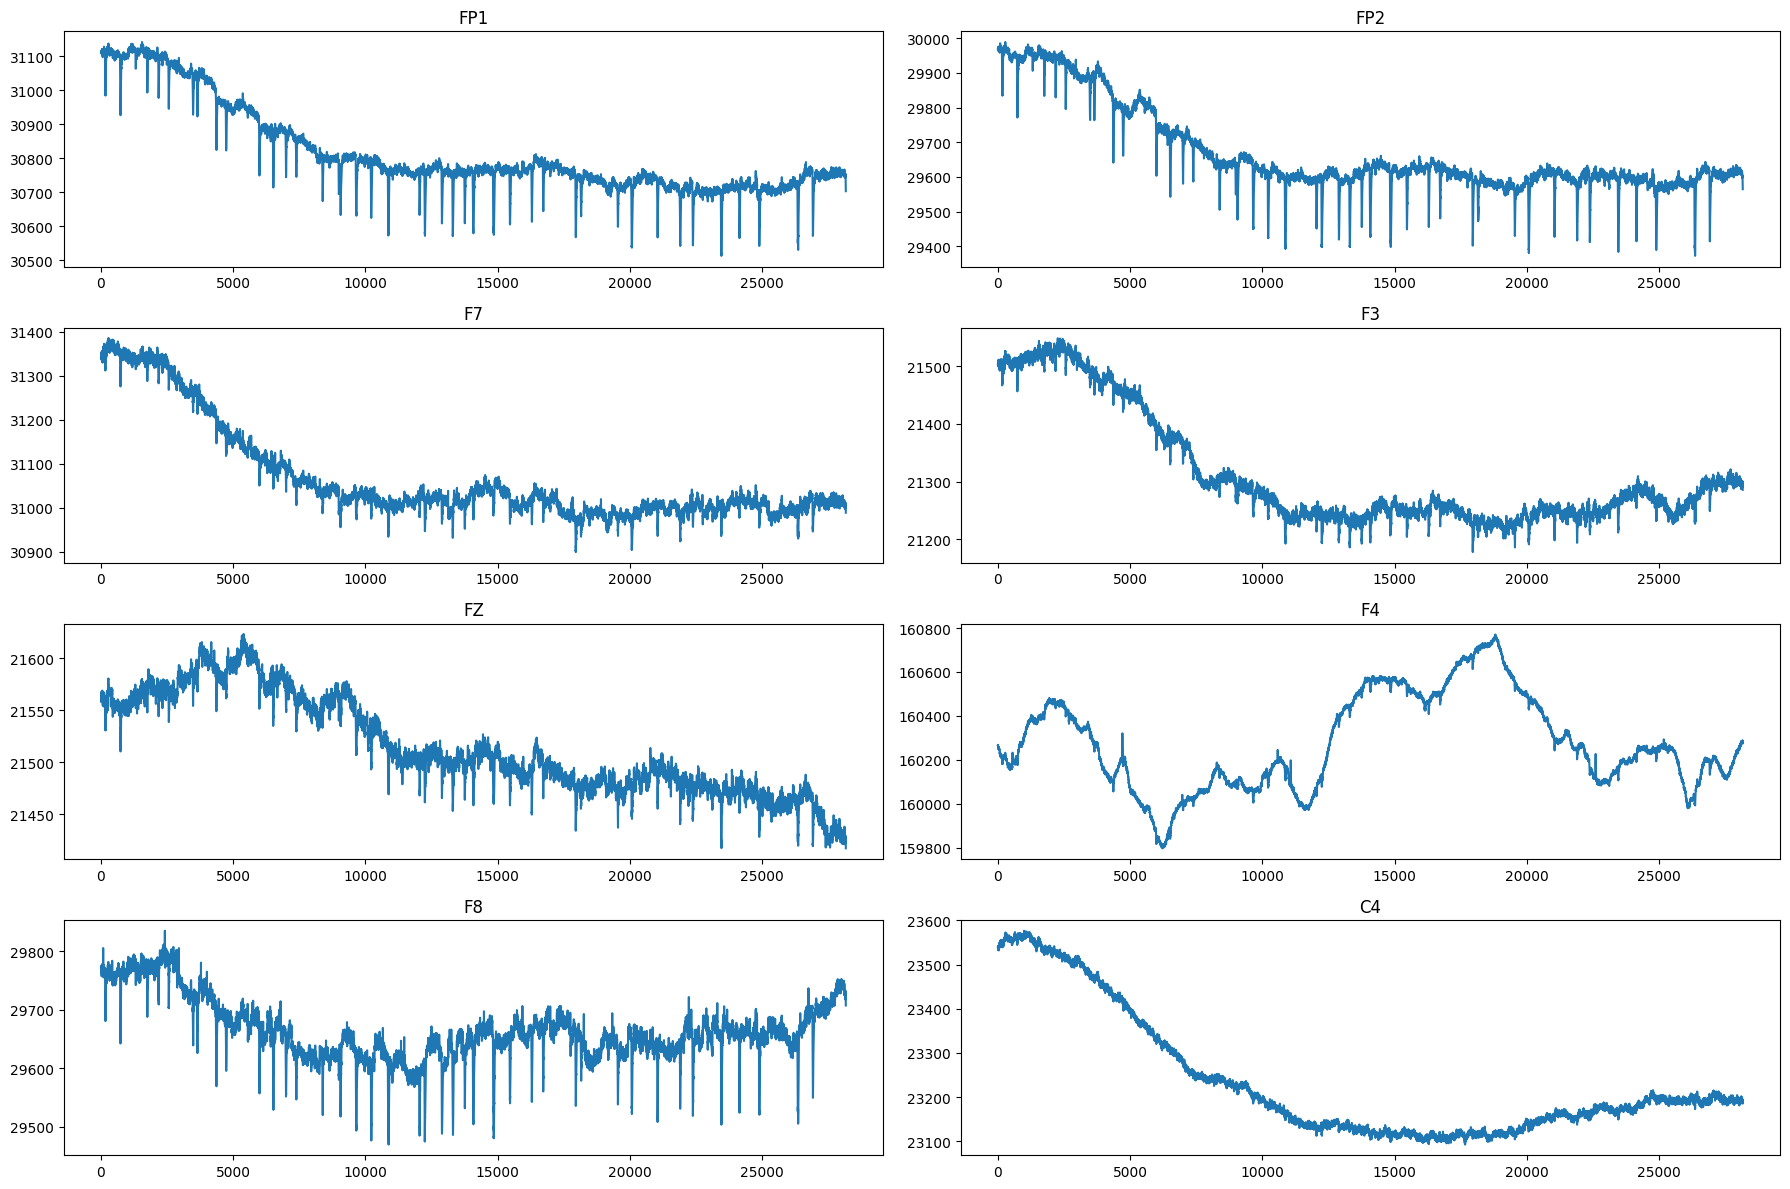

In [15]:
sample2 = pd.read_csv( "Dataset/Clean/Stroop/highlevel/highlevel_1.csv")
plt.figure(figsize=(18,12))

for i,col in enumerate(eeg_channels,start=1):

    plt.subplot(4,2,i)
    plt.plot(sample2[col])
    plt.title(col)

plt.tight_layout()
print("Stroop Data Graph")
plt.show()

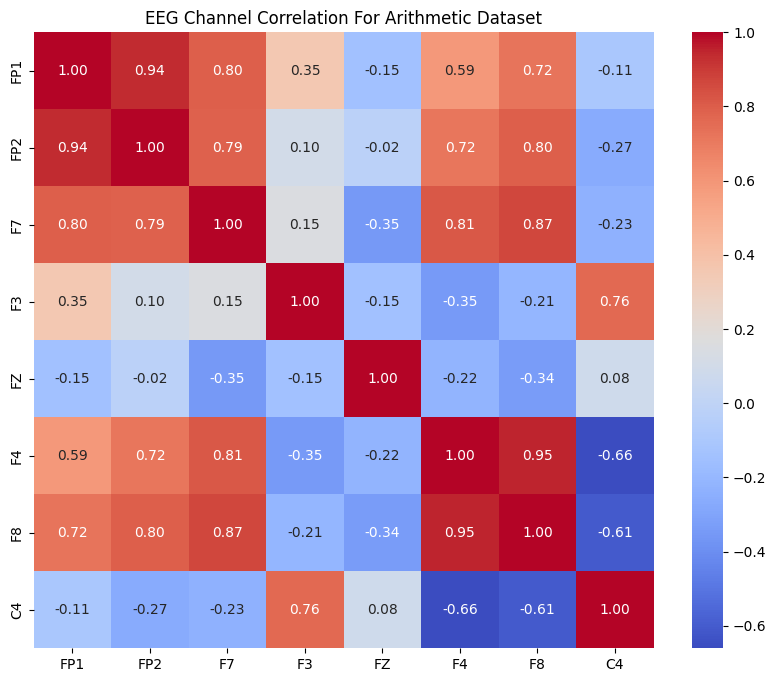

In [16]:
sample1 = pd.read_csv("Dataset/Clean/Arithmetic/highlevel/highlevel_1.csv")
corr = sample1[eeg_channels].corr()

plt.figure(figsize=(10,8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("EEG Channel Correlation For Arithmetic Dataset")
plt.show()

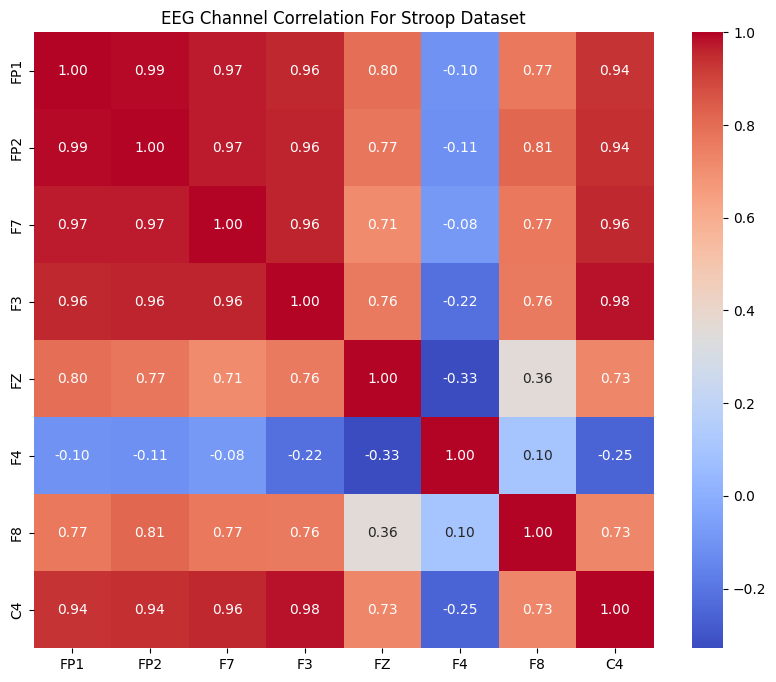

In [17]:
sample2 = pd.read_csv("Dataset/Clean/Stroop/highlevel/highlevel_1.csv")

corr = sample2[eeg_channels].corr()
plt.figure(figsize=(10,8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("EEG Channel Correlation For Stroop Dataset")
plt.show()

#### Plot EEG Window Function

In [18]:
def plot_eeg_window(df, start=0, window_size=3000):

    end = start + window_size
    signals = df[eeg_channels].iloc[start:end]

    plt.figure(figsize=(16,8))

    offset = 0

    for col in eeg_channels:
        signal = signals[col]

        # normalize only for plotting
        signal = (signal - signal.mean()) / signal.std()

        plt.plot(signal + offset,linewidth=0.8)
        offset += 5

    plt.yticks(np.arange(0, len(eeg_channels)*5, 5),eeg_channels)

    plt.xlabel("Samples")
    plt.ylabel("Channels")

    plt.title(f"EEG Window [{start}:{end}]")
    plt.grid(alpha=0.2)

    plt.show()

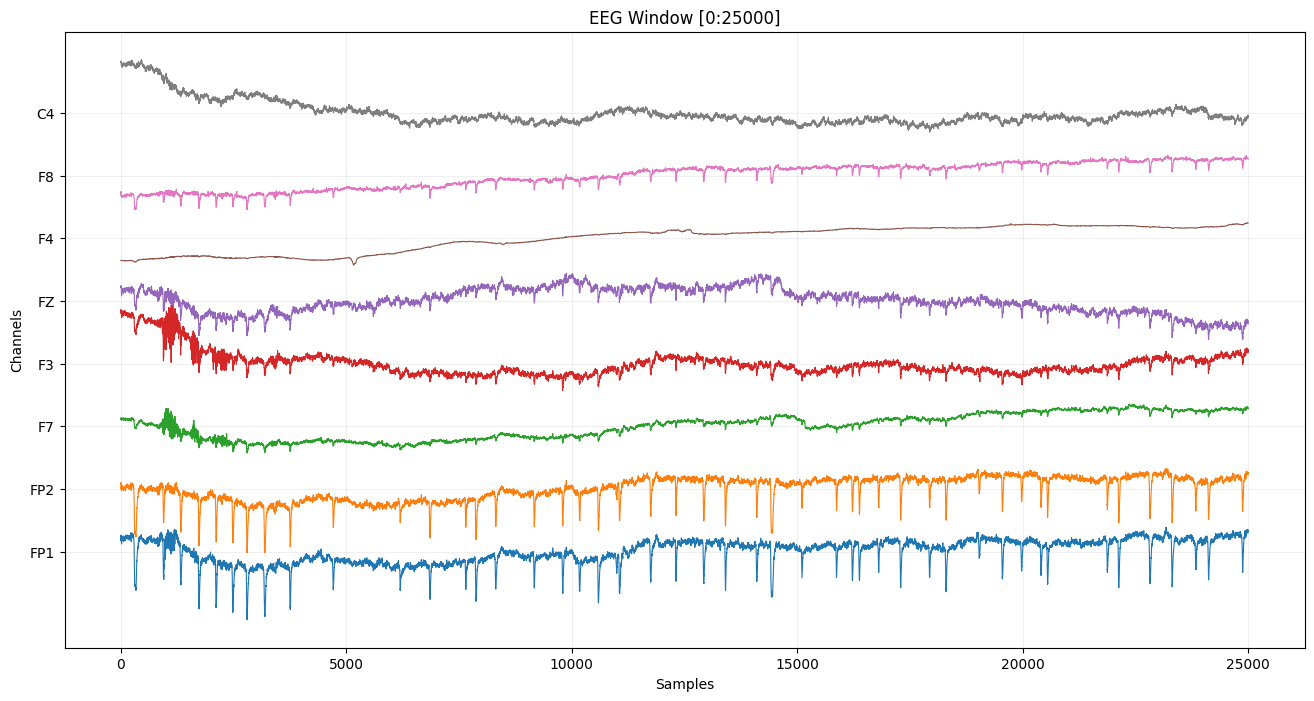

In [19]:
df = pd.read_csv("Dataset/Clean/Arithmetic/highlevel/highlevel_1.csv")
plot_eeg_window(df,start=0,window_size=25000)

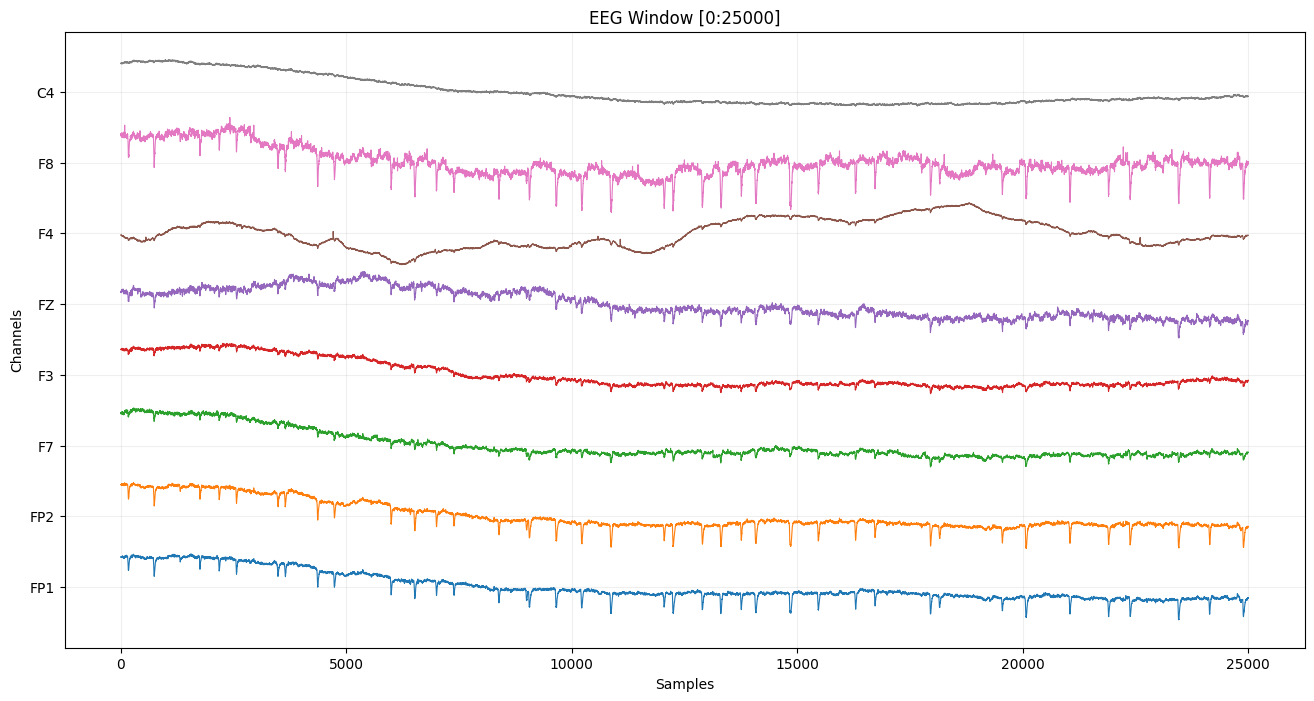

In [20]:
df = pd.read_csv("Dataset/Clean/Stroop/highlevel/highlevel_1.csv")
plot_eeg_window(df,start=0,window_size=25000)

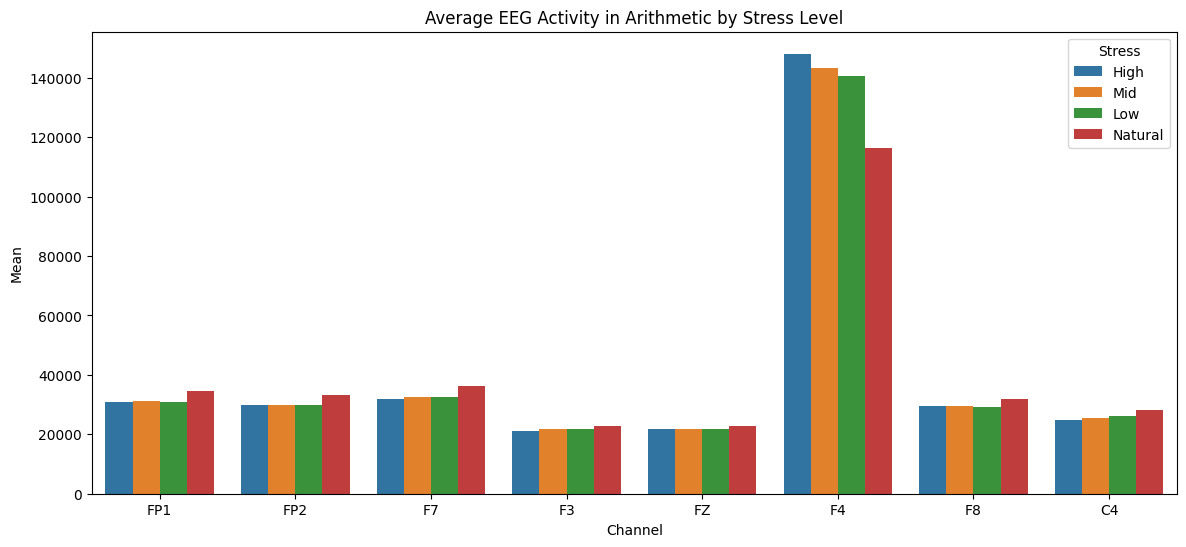

In [21]:
files1 = {
    "High": "Dataset/Clean/Arithmetic/highlevel/highlevel_1.csv",
    "Mid":"Dataset/Clean/Arithmetic/midlevel/midlevel_1.csv",
    "Low":"Dataset/Clean/Arithmetic/lowlevel/lowlevel_1.csv",
    "Natural":"Dataset/Clean/Arithmetic/natural/natural_1.csv"
}

rows = []

for label, path in files1.items():

    df = pd.read_csv(path)

    for channel in eeg_channels:

        rows.append({
            "Stress": label,
            "Channel": channel,
            "Mean": df[channel].mean()
        })

plot_df = pd.DataFrame(rows)

plt.figure(figsize=(14,6))

sns.barplot(
    data=plot_df,
    x="Channel",
    y="Mean",
    hue="Stress"
)

plt.title("Average EEG Activity in Arithmetic by Stress Level")
plt.show()

In [22]:
print(eeg_channels)

['FP1', 'FP2', 'F7', 'F3', 'FZ', 'F4', 'F8', 'C4']


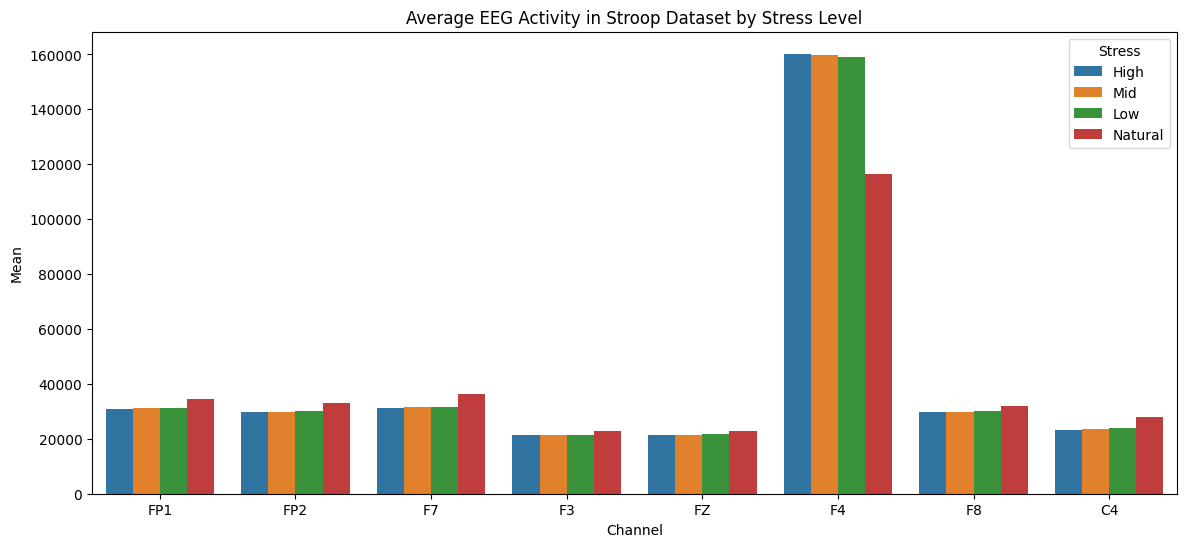

In [23]:
files2 = {
    "High":"Dataset/Clean/Stroop/highlevel/highlevel_1.csv",
    "Mid":"Dataset/Clean/Stroop/midlevel/midlevel_1.csv",
    "Low":"Dataset/Clean/Stroop/lowlevel/lowlevel_1.csv",
    "Natural":"Dataset/Clean/Stroop/natural/natural_1.csv"
}

rows = []

for label, path in files2.items():

    df = pd.read_csv(path)
    for channel in eeg_channels:

        rows.append({
            "Stress": label,
            "Channel": channel,
            "Mean": df[channel].mean()
        })

plot_df = pd.DataFrame(rows)

plt.figure(figsize=(14,6))

sns.barplot(
    data=plot_df,
    x="Channel",
    y="Mean",
    hue="Stress"
)

plt.title("Average EEG Activity in Stroop Dataset by Stress Level")
plt.show()

In [24]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("Dataset/Clean/Arithmetic/highlevel/highlevel_1.csv")

eeg_channels = [
    "FP1","FP2","F7","F3",
    "FZ","F4","F8","C4"
]

scaler = StandardScaler()

df[eeg_channels] = scaler.fit_transform(df[eeg_channels])

print(df[eeg_channels].describe().loc[["mean", "std"]])

               FP1           FP2            F7            F3            FZ  \
mean  6.876486e-14  4.400331e-14  2.294746e-15  3.124266e-15 -4.911997e-14   
std   1.000017e+00  1.000017e+00  1.000017e+00  1.000017e+00  1.000017e+00   

                F4            F8            C4  
mean  1.541201e-14 -7.845551e-15 -5.232951e-14  
std   1.000017e+00  1.000017e+00  1.000017e+00  


# Frequency Domain Feature Extraction

Welch Power Spectral Density (PSD) is used to compute band powers.

Frequency bands:

- Delta (0.5–4 Hz)
- Theta (4–8 Hz)
- Alpha (8–13 Hz)
- Beta (13–30 Hz)
- Gamma (30–45 Hz)

Total:

8 channels × 7 features = 56 features

8 channels × 5 bands = 40 features 

56 statistical features + 40 EEG frequency features = 96 features 

250 samples / 192 Hz ≈ 1.30 seconds

[Window size = 250]


In [25]:
from scipy.signal import welch

def extract_features(df, task_type, window_size=250, fs=250):

    bands = {
        "delta": (0.5, 4),
        "theta": (4, 8),
        "alpha": (8, 13),
        "beta":  (13, 30),
        "gamma": (30, 45)
    }

    feature_rows = []

    for start in range(0, len(df) - window_size, window_size):

        window = df.iloc[start : start + window_size]

        row = {}

        for col in eeg_channels:

            signal = window[col]

            # Statistical Features
            row[f"{col}_mean"] = signal.mean()
            row[f"{col}_std"] = signal.std()
            row[f"{col}_min"] = signal.min()
            row[f"{col}_max"] = signal.max()
            row[f"{col}_range"] = (signal.max() - signal.min())
            row[f"{col}_var"] = signal.var()
            row[f"{col}_rms"] = np.sqrt(np.mean(signal**2))

            # Frequency Features
            freqs, psd = welch( signal.values, fs=fs, nperseg=min(len(signal), 128) )

            for band_name, (low, high) in bands.items():

                mask = ((freqs >= low) & (freqs < high))

                row[f"{col}_{band_name}"] = np.trapezoid( psd[mask], freqs[mask])

        row["Stress_Level"] = (window["Stress_Level"].iloc[0])
        row["Subject_ID"] = (window["Subject_ID"].iloc[0])
        row["Task_Type"] = task_type
        feature_rows.append(row)

    return pd.DataFrame(feature_rows)

In [26]:
all_feature_dfs = []
tasks = ["Arithmetic", "Stroop"]

for task in tasks:
    base_dir = f"Dataset/Clean/{task}"
    for category in os.listdir(base_dir):

        category_path = os.path.join(base_dir,category)
        if not os.path.isdir(category_path): continue

        for file in os.listdir(category_path):

            if not file.endswith(".csv"): continue

            filepath = os.path.join(category_path,file)
            df = pd.read_csv(filepath)

            scaler = StandardScaler()
            df[eeg_channels] = scaler.fit_transform(df[eeg_channels])

            feature_df = extract_features(
                df,
                task_type=task,
                window_size=250,
                fs=df["Sampling_Rate"].iloc[0]
            )
            all_feature_dfs.append(feature_df)

final_dataset = pd.concat(all_feature_dfs,ignore_index=True)

print(final_dataset.shape)
print(final_dataset.columns)
print(final_dataset["Stress_Level"].value_counts())

(11036, 99)
Index(['FP1_mean', 'FP1_std', 'FP1_min', 'FP1_max', 'FP1_range', 'FP1_var',
       'FP1_rms', 'FP1_delta', 'FP1_theta', 'FP1_alpha', 'FP1_beta',
       'FP1_gamma', 'FP2_mean', 'FP2_std', 'FP2_min', 'FP2_max', 'FP2_range',
       'FP2_var', 'FP2_rms', 'FP2_delta', 'FP2_theta', 'FP2_alpha', 'FP2_beta',
       'FP2_gamma', 'F7_mean', 'F7_std', 'F7_min', 'F7_max', 'F7_range',
       'F7_var', 'F7_rms', 'F7_delta', 'F7_theta', 'F7_alpha', 'F7_beta',
       'F7_gamma', 'F3_mean', 'F3_std', 'F3_min', 'F3_max', 'F3_range',
       'F3_var', 'F3_rms', 'F3_delta', 'F3_theta', 'F3_alpha', 'F3_beta',
       'F3_gamma', 'FZ_mean', 'FZ_std', 'FZ_min', 'FZ_max', 'FZ_range',
       'FZ_var', 'FZ_rms', 'FZ_delta', 'FZ_theta', 'FZ_alpha', 'FZ_beta',
       'FZ_gamma', 'F4_mean', 'F4_std', 'F4_min', 'F4_max', 'F4_range',
       'F4_var', 'F4_rms', 'F4_delta', 'F4_theta', 'F4_alpha', 'F4_beta',
       'F4_gamma', 'F8_mean', 'F8_std', 'F8_min', 'F8_max', 'F8_range',
       'F8_var', 'F8_rms', '

In [27]:
filepath = "Dataset/Train/ML/final_dataset.csv"
os.makedirs(os.path.dirname(filepath),exist_ok=True)

final_dataset.to_csv(filepath, index=False)

##### Stress_Level ( This is our target feature: )
##### Subject_ID ( Needed for: GroupShuffleSplit, GroupKFold ) to prevent data leakage. Not a feature, but extremely important.
##### Task_Type ( Arithmetic + Stroop )